In [44]:
%pip install numpy matplotlib nbconvert pandadoc scipy lalsuite gwpy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import kalman
kalman.set_debug(0)

import kalman.chrono as chrono

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Linear Kalman Filter: Ballistic Projectile Model 1D

KalmanStateModel(fs = 256Hz):

    Ballistic State Model (v1.0)
        State model for ballistic trajectories, simulating
        the motion of a projectile under the
        influence of gravity with constant
        acceleration.

    Dimensions Summary:
        State Vector....................................: 3 dims
        Control Input...................................: 1 dim
        Observation.....................................: 1 dim

    Initial State:
        State Vector (x0)...............................: 3x1 dims
        State Covariance (P0)...........................: 3x3 dims

    Matrix Information:
        System Dynamics F (also known as A).............: 3x3 dims
        Observation Matrix H (also known as C)..........: 1x3 dims

        Control Input B (also known as U)...............: 3x1 dims
        Process Noise Covariance Q (also known as W)....: 3x3 dims
        Measurement Noise Covariance R (also known as V): 1x1 dims

Chrono summary:
 1. Model initial

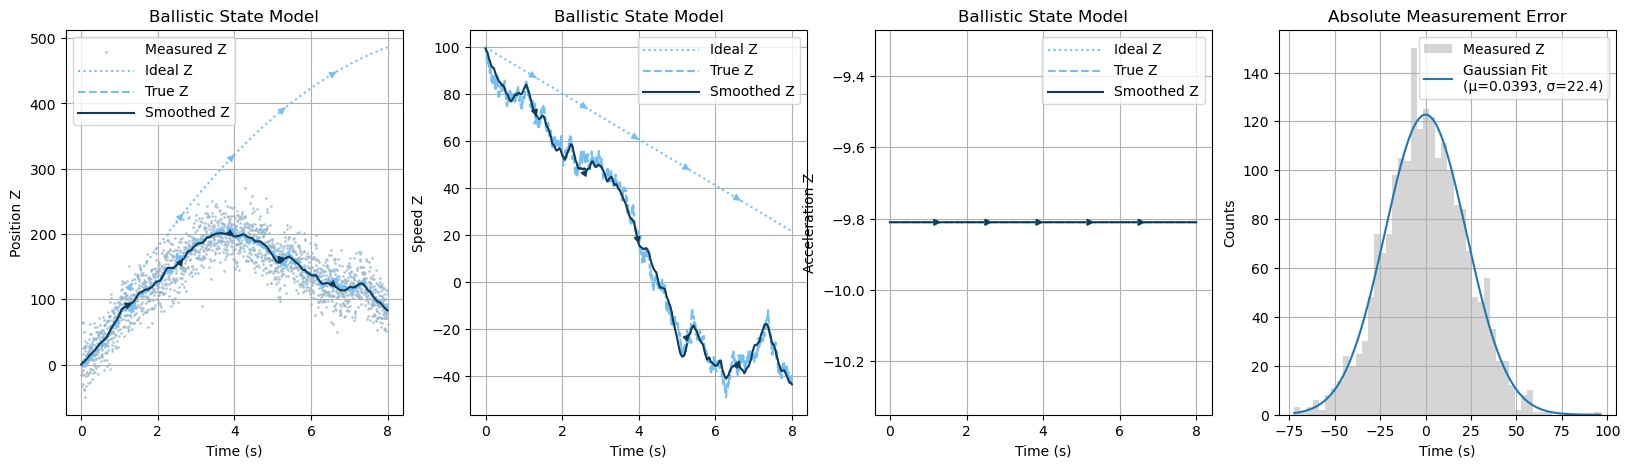

In [45]:
from kalman.models import BallisticStateModel

bulletbill = BallisticStateModel(dim=1, sample_rate=256, measurement_uncertainty=500, process_uncertainty=1, random_seed=42)
bulletbill.initial_state([0, 100, -9.81]) # Initial state: [z, vz, az]
bulletbill.print()

chrono.restart()
chrono.lap("Model initialized")
sample = bulletbill.sample(8)
chrono.lap("Sampling completed")
record = bulletbill.filter(sample, smooth=True, reset=True)
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(4, 1)

record.plot(sample=sample, fig=canvas[0], component="position")
chrono.lap("Position plot completed")
record.plot(sample=sample, fig=canvas[1], component="speed")
chrono.lap("Speed plot completed")
record.plot(sample=sample, fig=canvas[2], component="acceleration")
chrono.lap("Acceleration plot completed")

record.plot_error(sample=sample, fig=canvas[3])
chrono.summary()

Sampling & filtering completed for #2/2: 0.328451s
KalmanStateCollection with 2 records: 
  0: KalmanStateRecord(N=2048, n=3, m=1, flavor=Smoothed, model=Ballistic State Model)
  1: KalmanStateRecord(N=2048, n=3, m=1, flavor=Smoothed, model=Ballistic State Model)


(<Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>,
 <Axes: title={'center': 'Ballistic State Model'}, xlabel='Time (s)', ylabel='Position Z'>)

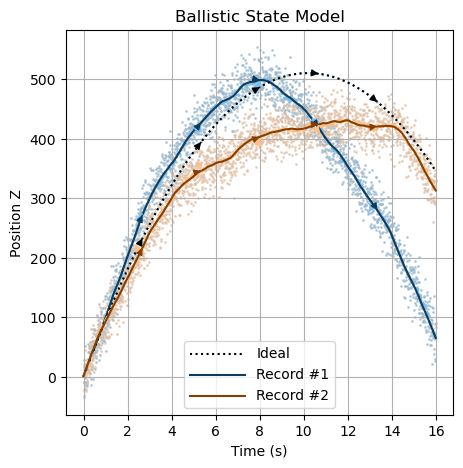

In [46]:
from kalman.models import BallisticStateModel
from kalman import KalmanStateCollection

bulletbill = BallisticStateModel(dim=1, sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5)
bulletbill.initial_state([0, 100, -9.81]) # Initial state: [z, vz, az]

chrono.restart()
chrono.lap("Model initialized")

N = 2
samples = []
collection = []
for i in range(N):

    samples.append(bulletbill.sample(16))
    collection.append(bulletbill.filter(samples[-1], smooth=True, reset=True))
    if i % 4 == 0 or i == N-1:
        print(chrono.lap(f"Sampling & filtering completed for #{i+1}/{N}"), end="\r" if i < N-1 else "\n")

collection = KalmanStateCollection(collection)
collection.print()

collection.plot(samples=samples, component="position")

## Linear Kalman Filter: Ballistic Projectile Model 3D

Chrono summary:
 1. Model initialized: 0.000210s (ΔT=0.000210s)
 2. Sampling completed: 0.106405s (ΔT=0.106195s)
 3. Filtering completed: 0.193169s (ΔT=0.086764s)
 4. Position plot completed: 0.361111s (ΔT=0.167942s)
 5. Speed plot completed: 0.433981s (ΔT=0.072870s)
 6. Correlation plot completed: 0.450219s (ΔT=0.016238s)

==> Total elapsed: 0.450231s



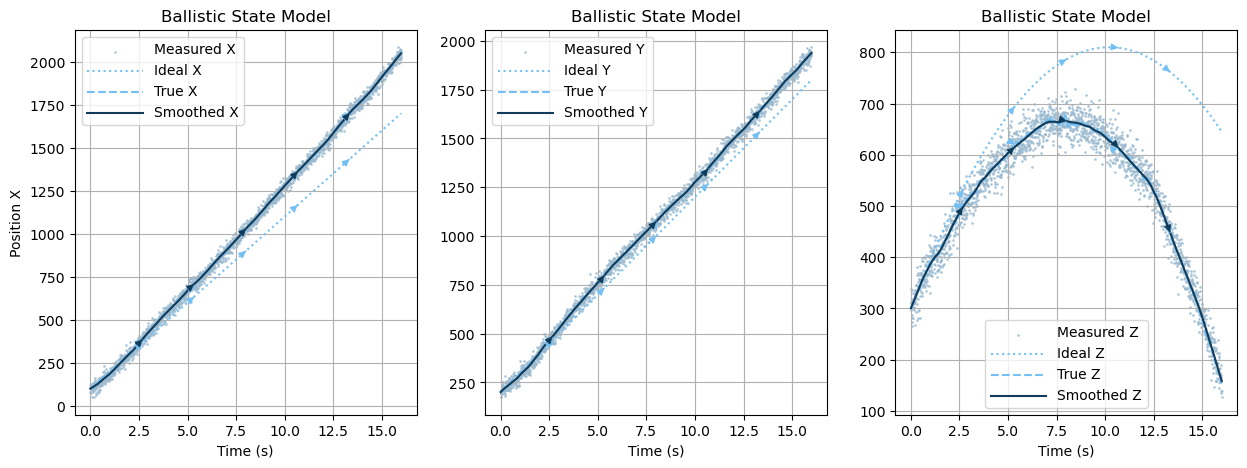

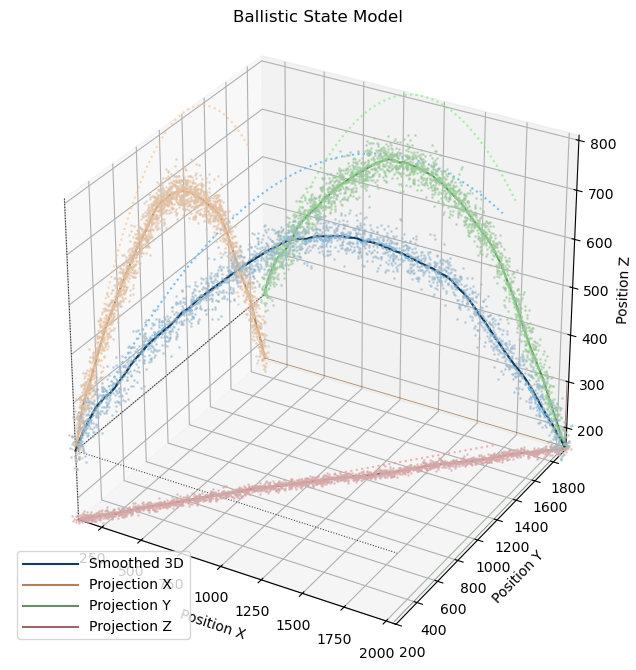

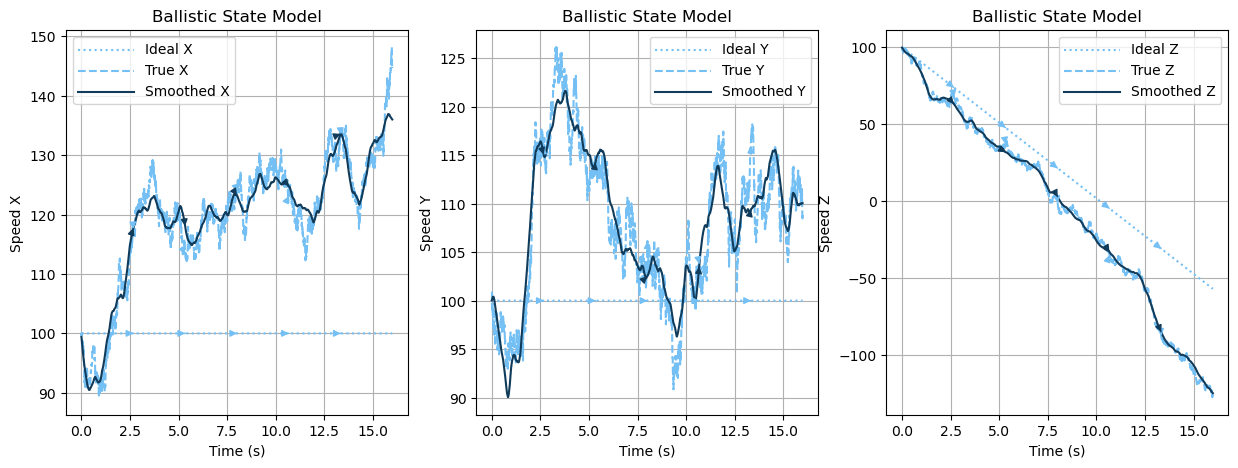

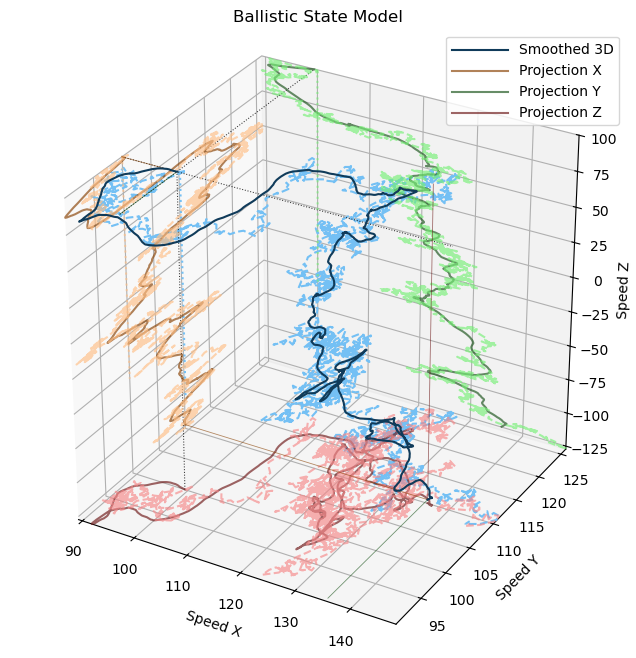

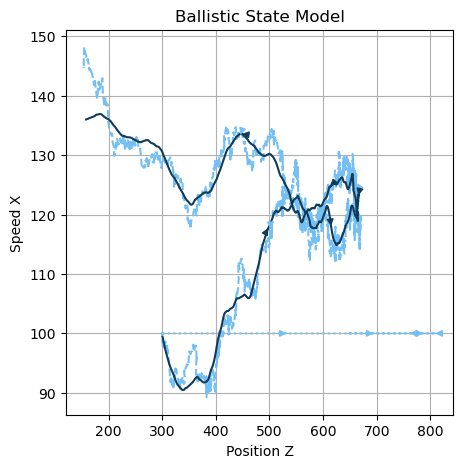

In [67]:
chrono.restart()

from kalman.models import BallisticStateModel
bulletbill = BallisticStateModel(dim=3, sample_rate=128, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
bulletbill.initial_state([
    [100, 100, 0],    # Initial state: [x, vx, ax] 
    [200, 100, 0],    # Initial state: [y, vy, ay]
    [300, 100, -9.81] # Initial state: [z, vz, az]
])
# bulletbill.print()
chrono.lap("Model initialized")

sample = bulletbill.sample(16)
chrono.lap("Sampling completed")

record = bulletbill.filter(sample.zk, smooth=True, reset=True)
# record.print()
chrono.lap("Filtering completed")

from kalman.helpers import get_canvas
canvas = get_canvas(3, 1)
record.plot(sample=sample, component="position", dim=0, fig=canvas[0])
record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey = True)
record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey = True)
record.plot(sample=sample, component="position")
chrono.lap("Position plot completed")

canvas = get_canvas(3, 1)
record.plot(sample=sample, component="speed", dim=0, fig=canvas[0])
record.plot(sample=sample, component="speed", dim=1, fig=canvas[1])
record.plot(sample=sample, component="speed", dim=2, fig=canvas[2])
record.plot(sample=sample, component=["speed", "speed", "speed"])
chrono.lap("Speed plot completed")

record.plot(sample=sample, component=["position", "speed"], dim=[2,0])
chrono.lap("Correlation plot completed")

chrono.summary()

## Linear Kalman Filter: Ballistic Projectile Model 3D (Composite Factorization)

In [ ]:
# chrono.restart()

# from kalman.models import BallisticCompositeModel
# bulletbill = BallisticCompositeModel(dim=3, sample_rate=256, measurement_uncertainty=500, process_uncertainty=0.5, random_seed=42)
# bulletbill.initial_state([
#     [100, 100, 0],    # Initial state: [x, vx, ax] 
#     [200, 100, 0],    # Initial state: [y, vy, ay]
#     [300, 100, -9.81] # Initial state: [z, vz, az]
# ])
# bulletbill.print()
# chrono.lap("Model initialized")

# sample = bulletbill.sample(16)
# chrono.lap("Sampling completed")

# record = bulletbill.filter(sample.zk, smooth=False, reset=True)
# record.print()
# chrono.lap("Filtering completed")

# from kalman.helpers import get_canvas
# canvas = get_canvas(3, 1)
# record.plot(sample=sample, component="position", dim=0, fig=canvas[0])
# record.plot(sample=sample, component="position", dim=1, fig=canvas[1], sharey = True)
# record.plot(sample=sample, component="position", dim=2, fig=canvas[2], sharey = True)
# record.plot(sample=sample, component="position")
# chrono.lap("Position plot completed")

# canvas = get_canvas(3, 1)
# record.plot(sample=sample, component="speed", dim=0, fig=canvas[0])
# record.plot(sample=sample, component="speed", dim=1, fig=canvas[1])
# record.plot(sample=sample, component="speed", dim=2, fig=canvas[2])
# record.plot(sample=sample, component=["speed", "speed", "speed"])
# chrono.lap("Speed plot completed")

# chrono.summary()

## Power Grid 50/60Hz Model

## Violin Suspension Model